# Mean-Reversion Indicators — Visual Scenarios: `btcusdt@4h`

Sanity-check **before** any performance metric: each indicator's anchor levels on a ~2-month price window with the signal beneath, the volume-at-price profile + its modes, and full-sample signal distributions. Contrarian reading throughout (fade when the signal is far from 0). *Future:* split the distributions by trend regime (bull/bear/chop) to see if the signal needs regime-specific calibration.

In [2]:
import sys
sys.path[:0] = ['C:\\Users\\SamuelAhou\\Documents\\operator', 'C:\\Users\\SamuelAhou\\Documents\\operator\\research\\mean_reversion']
import warnings
warnings.filterwarnings('ignore')
import mr_viz as V
from src.signals import mean_reversion as mr
SPEC = {'kind': 'bars', 'asset_type': 'perps', 'source': 'binance', 'symbol': 'btcusdt', 'timeframe': '4h'}
ASSET = 'crypto'
WIN = ('2024-03-01', '2024-05-01')
df = V.load(SPEC)
w = df.loc[WIN[0]:WIN[1]]
print(f"{SPEC['symbol']} {SPEC['timeframe']}: {len(df)} bars "
      f"{df.index.min().date()}->{df.index.max().date()}; scenario {WIN} = {len(w)} bars")
# Signals computed causally on the full series, sliced to the window for plotting.
piv = mr.pivot_deviations(df, timeframe=SPEC['timeframe'], asset_class=ASSET, lookback=7, n_pivots=5)
pzs = (piv['low_z'] - piv['high_z']).rename('pivot_zscore')
bb = mr.bollinger(df['close'], window=20, k=2.0)
vw = mr.vwap(df, window=20, k=2.0)
ou = mr.ou_score(df['close'], window=63)

btcusdt 4h: 14190 bars 2019-12-31->2026-06-21; scenario ('2024-03-01', '2024-05-01') = 372 bars


## 1. Price pivots (JASON)
Levels = weighted high/low pivots and their vol-projected `json2` bands; signal = `low_z − high_z`.

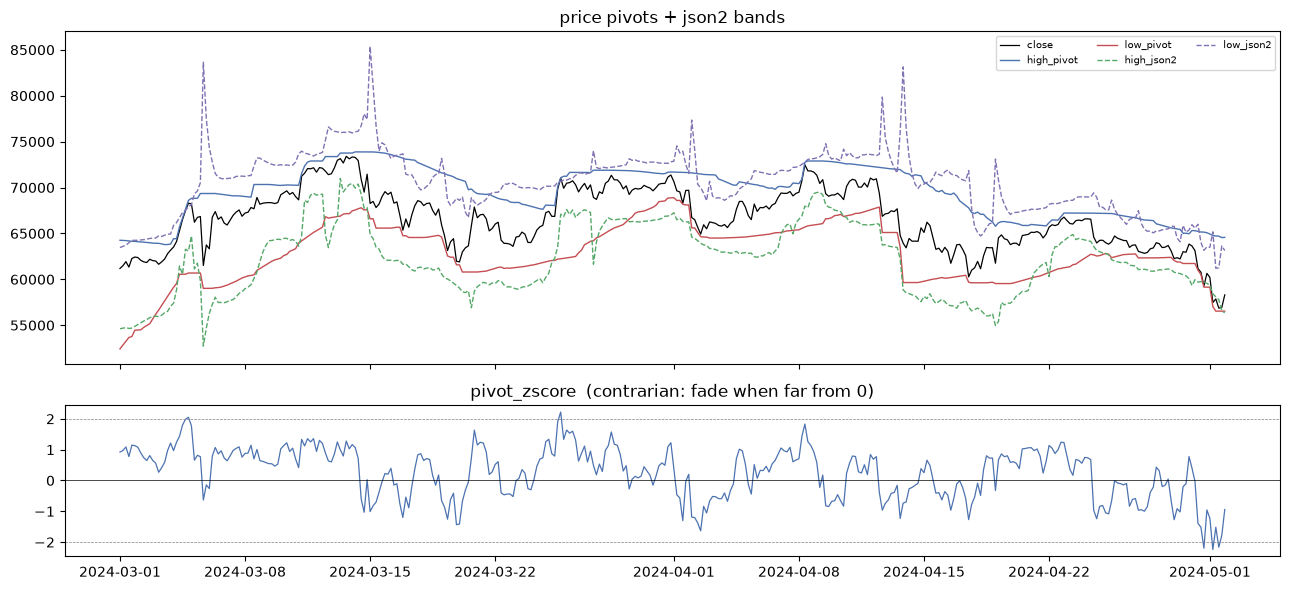

In [3]:
V.levels_panel(w['close'],
    {k: piv[k].loc[WIN[0]:WIN[1]] for k in ['high_pivot','low_pivot','high_json2','low_json2']},
    pzs.loc[WIN[0]:WIN[1]], 'price pivots + json2 bands', 'pivot_zscore')

## 2. Bollinger (MA ± kσ)
Anchor = 20-bar MA; bands = ±2σ; signal = `(close−MA)/σ`.

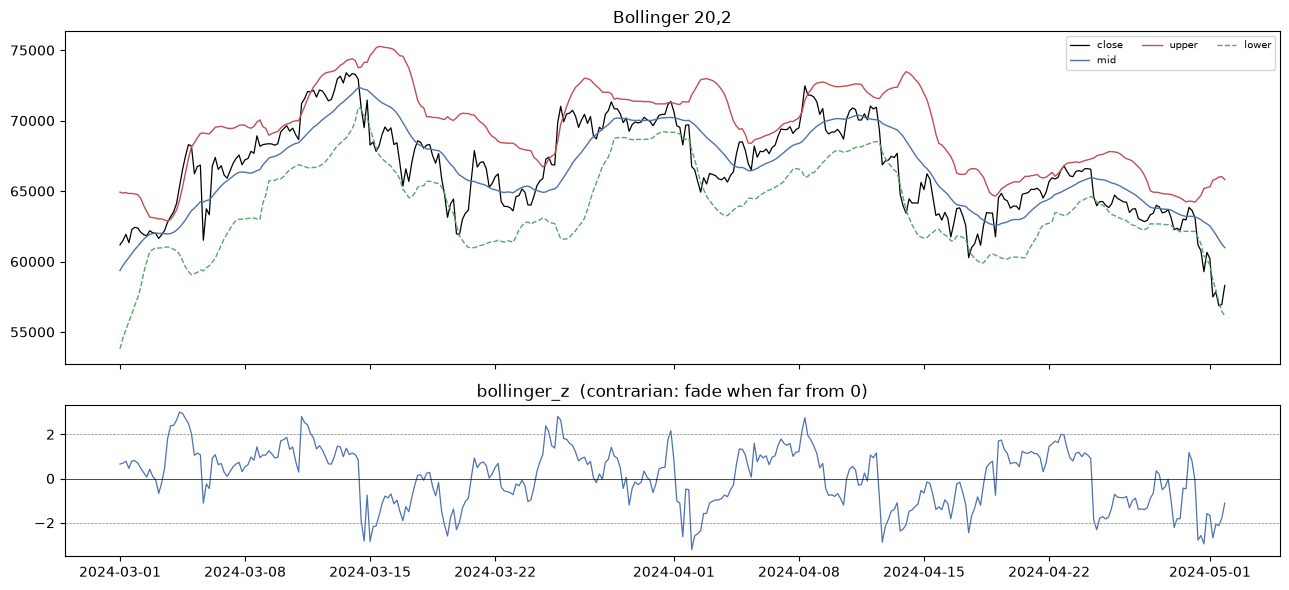

In [4]:
V.levels_panel(w['close'],
    {k: bb[k].loc[WIN[0]:WIN[1]] for k in ['mid','upper','lower']},
    bb['bollinger_z'].loc[WIN[0]:WIN[1]], 'Bollinger 20,2', 'bollinger_z')

## 3. VWAP deviation
Anchor = 20-bar volume-weighted price; bands = ±2σ of the deviation.

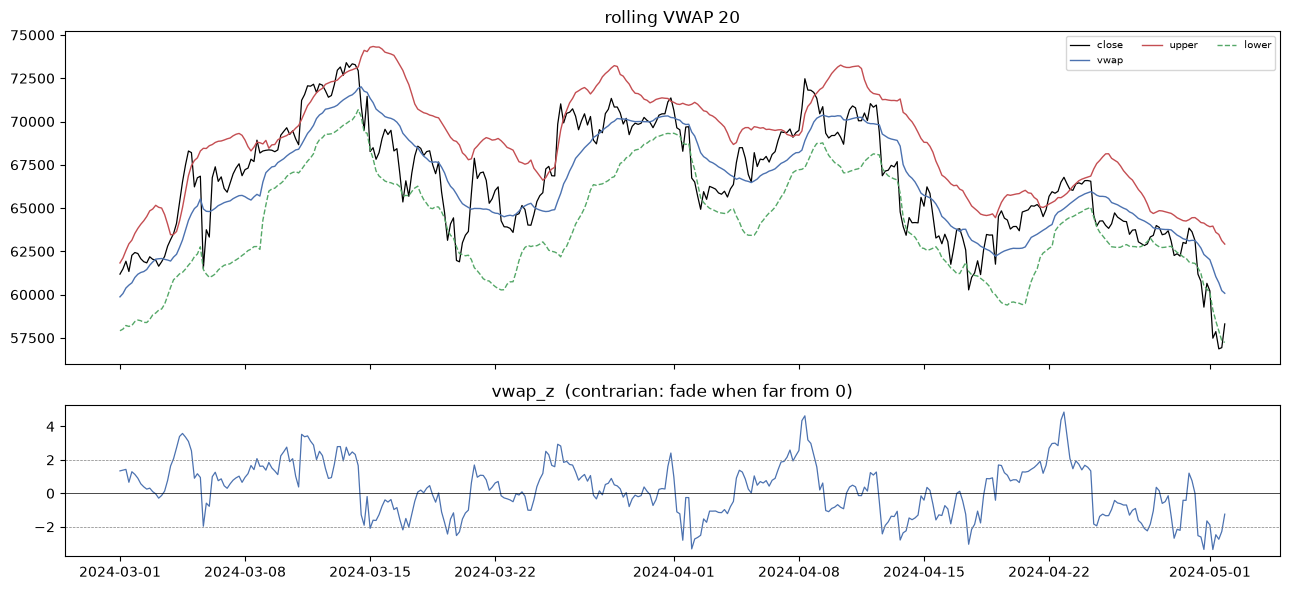

In [5]:
V.levels_panel(w['close'],
    {k: vw[k].loc[WIN[0]:WIN[1]] for k in ['vwap','upper','lower']},
    vw['vwap_z'].loc[WIN[0]:WIN[1]], 'rolling VWAP 20', 'vwap_z')

## 4. OU / Avellaneda–Lee s-score
Anchor = rolling OU equilibrium; signal = standardized deviation `s`. (Half-life shown in the distributions section.)

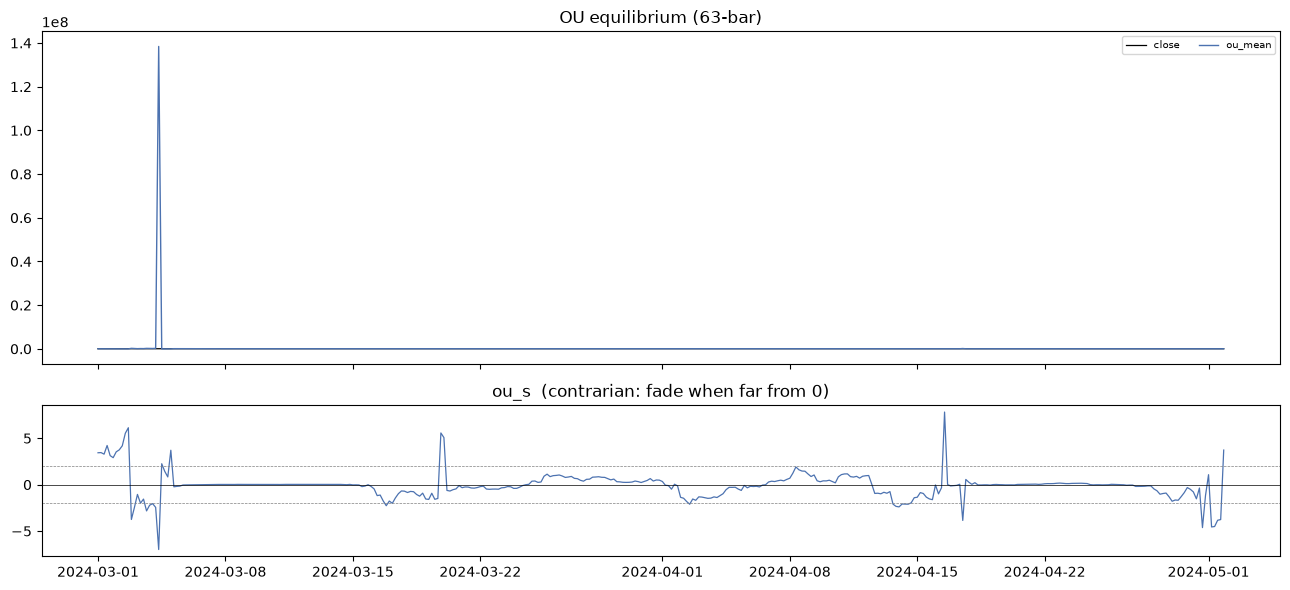

In [6]:
V.levels_panel(w['close'],
    {'ou_mean': ou['ou_mean'].loc[WIN[0]:WIN[1]]},
    ou['ou_s'].loc[WIN[0]:WIN[1]], 'OU equilibrium (63-bar)', 'ou_s')

## 5. Volume-profile modes
Volume-at-price over the window; **major/minor modes** via DP-GMM (KDE cross-check below). Deviations from these modes are the signal.

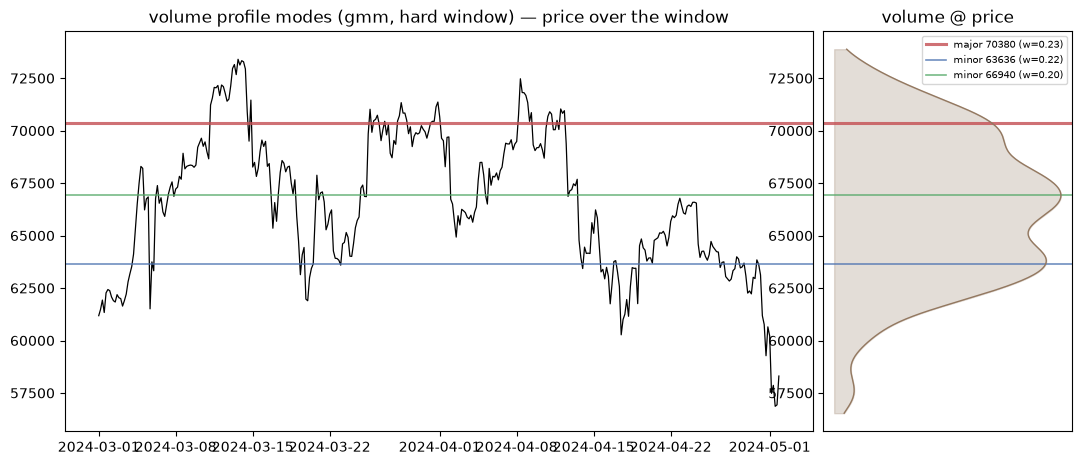

In [7]:
V.volume_profile_panel(w, method='gmm')

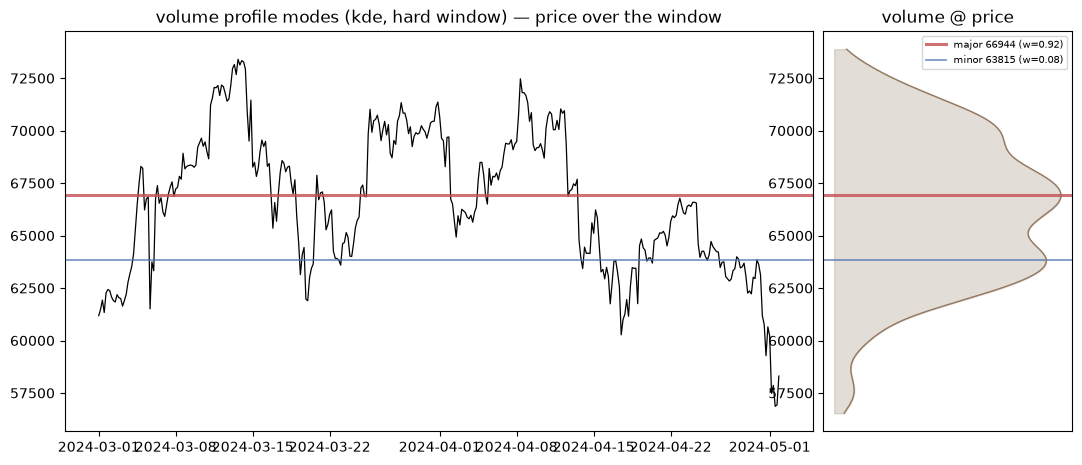

In [8]:
V.volume_profile_panel(w, method='kde')

### 5b. Deviation z-score **per mode** (the volume 'pivots')

One z per mode — `z_mode_k = (close − μ_k)/σ_k` in each node's own width. Two modes ⇒ `z_mode_1` (major) and `z_mode_2` (minor), the volume analog of a pivot z per pivot. Both mode levels are overlaid on price; both z's beneath. Profile recomputed every few bars.

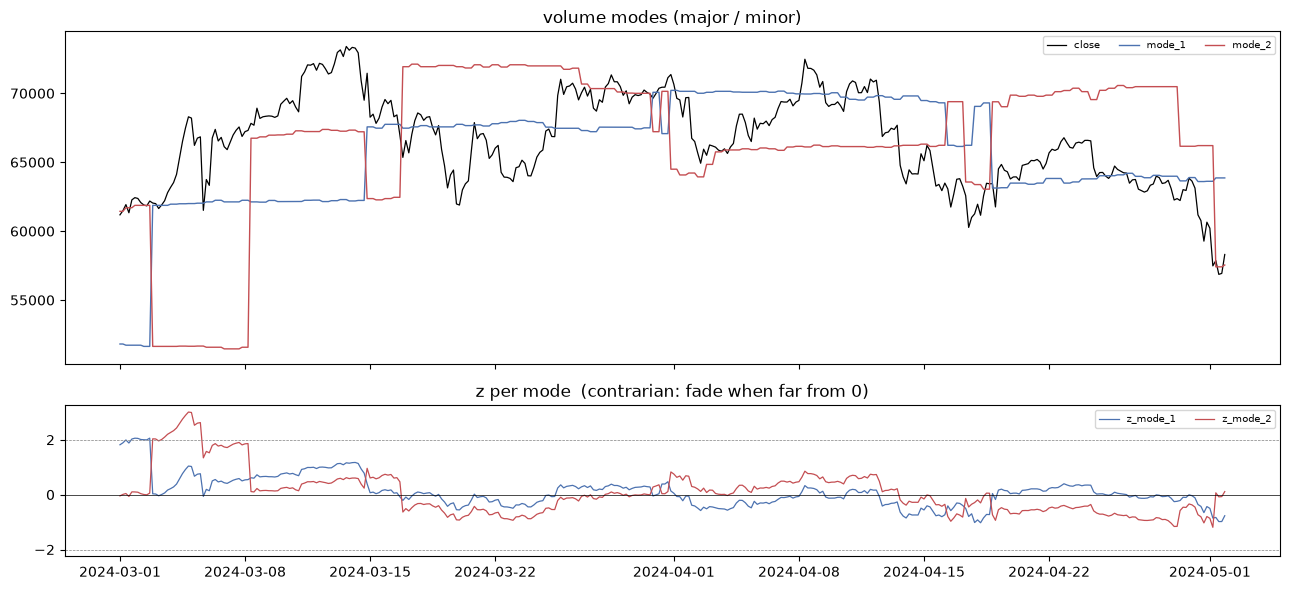

In [9]:
vmd = mr.volume_mode_deviations(df, window=90, method='kde', n_modes=2, step=3)
V.levels_panel(w['close'],
    {k: vmd[k].loc[WIN[0]:WIN[1]] for k in ['mode_1', 'mode_2']},
    {k: vmd[k].loc[WIN[0]:WIN[1]] for k in ['z_mode_1', 'z_mode_2']},
    'volume modes (major / minor)', 'z per mode')

### 5c. Hard window vs soft (exponential-decay) memory

The profile above uses a **hard** trailing window (equal weight, sharp cutoff → when a big-volume bar drops out, the mode *jumps*). A **soft exp-decay** ages old volume out smoothly (half-life memory, no dropout). Below: static profiles hard vs soft, then the major-mode level + its z over time both ways — watch for the hard version's discontinuous jumps.

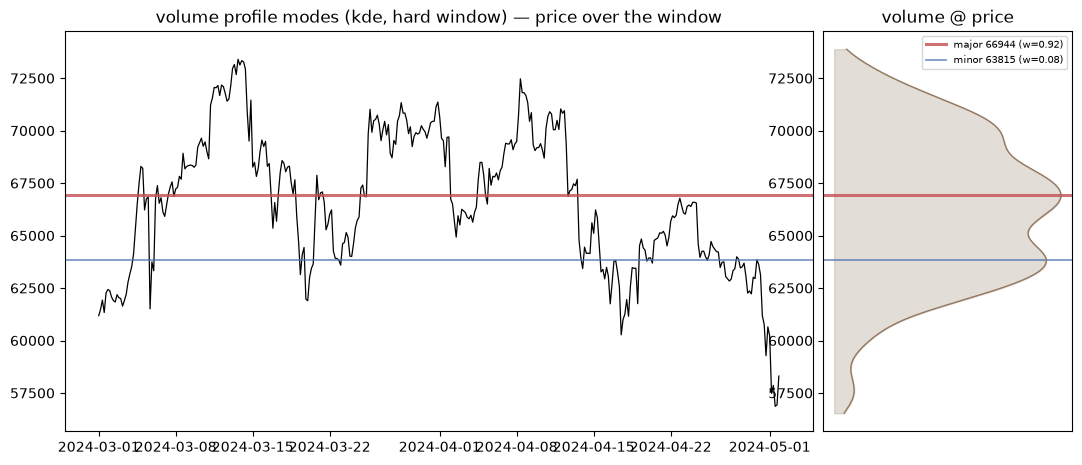

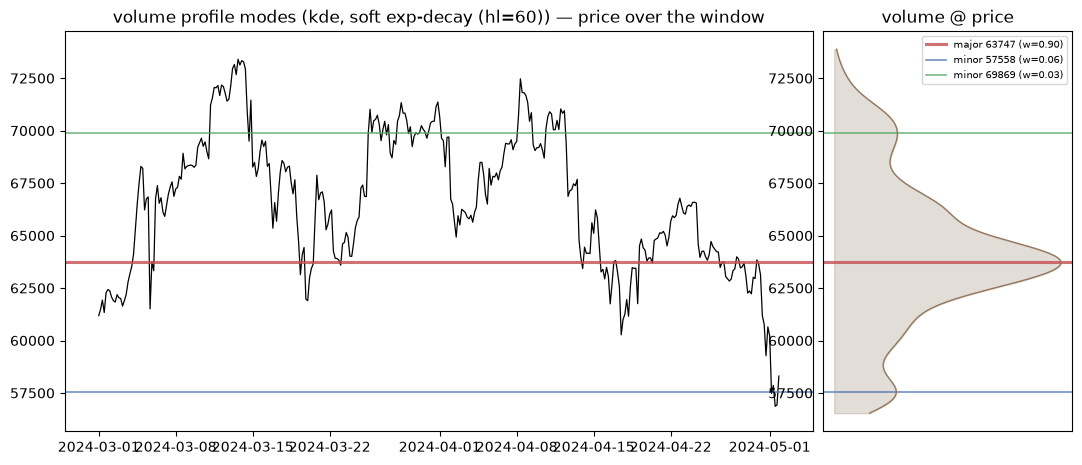

In [14]:
V.volume_profile_panel(w, method='kde')                      # hard window
V.volume_profile_panel(w, method='kde', decay_halflife=60)    # soft exp-decay

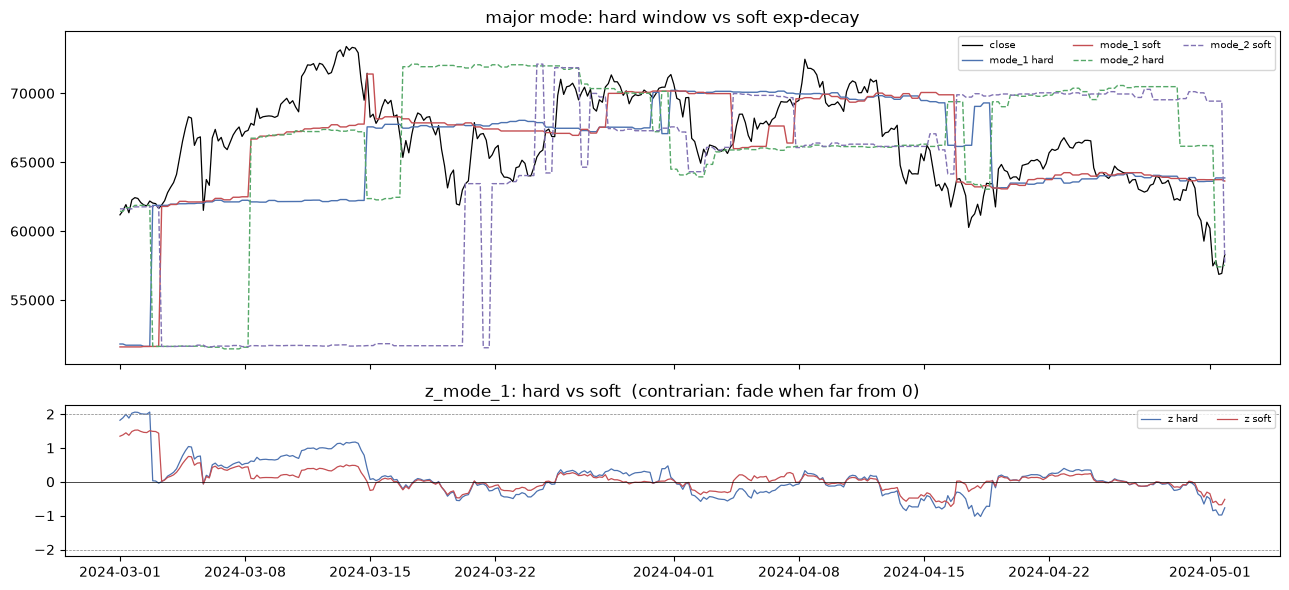

In [15]:
vmd_soft = mr.volume_mode_deviations(df, window=180, method='kde', n_modes=2,
                                      step=3, decay_halflife=45)
V.levels_panel(w['close'],
    {'mode_1 hard': vmd['mode_1'].loc[WIN[0]:WIN[1]], 'mode_1 soft': vmd_soft['mode_1'].loc[WIN[0]:WIN[1]], 'mode_2 hard': vmd['mode_2'].loc[WIN[0]:WIN[1]], 'mode_2 soft': vmd_soft['mode_2'].loc[WIN[0]:WIN[1]]},
    {'z hard': vmd['z_mode_1'].loc[WIN[0]:WIN[1]], 'z soft': vmd_soft['z_mode_1'].loc[WIN[0]:WIN[1]]},
    'major mode: hard window vs soft exp-decay', 'z_mode_1: hard vs soft')

## 6. Signal distributions (full sample)
Shape of each signal over all history — what 'extreme' means per signal. *Next:* condition these on bull/bear/chop regime.

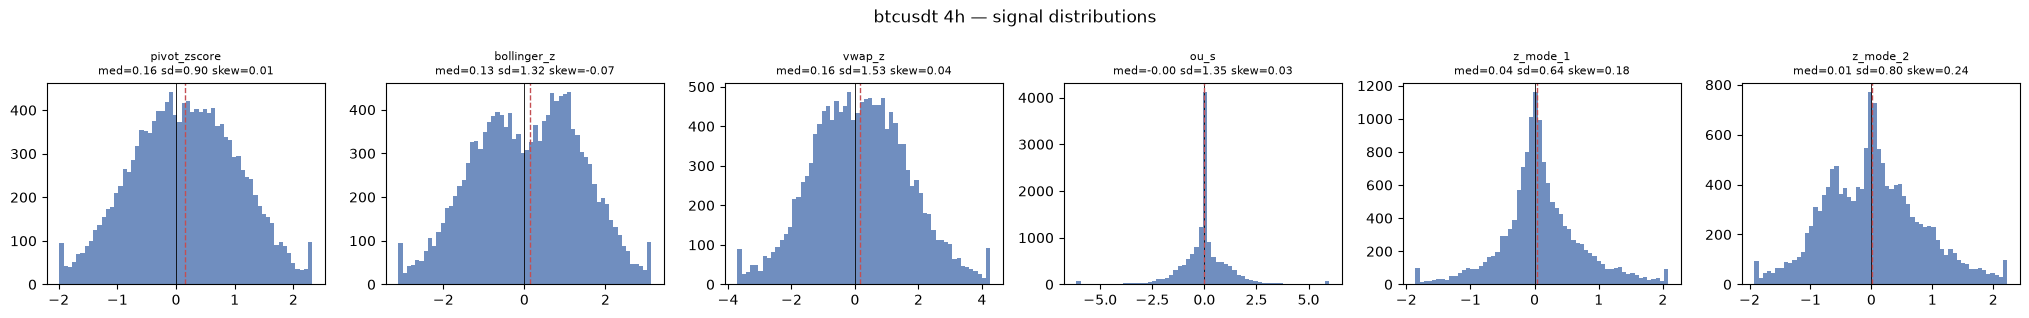

In [12]:
V.distributions_panel({'pivot_zscore': pzs, 'bollinger_z': bb['bollinger_z'],
    'vwap_z': vw['vwap_z'], 'ou_s': ou['ou_s'],
    'z_mode_1': vmd['z_mode_1'], 'z_mode_2': vmd['z_mode_2']},
    f"{SPEC['symbol']} {SPEC['timeframe']} — signal distributions")

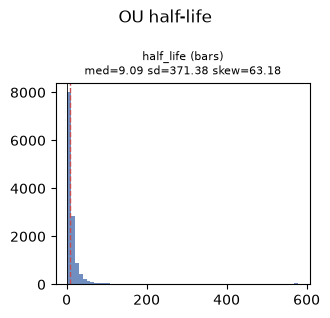

In [13]:
V.distributions_panel({'half_life (bars)': ou['half_life']}, 'OU half-life')